# EA SPORTS FC 27 – játékosok statisztikai elemzése

**Szorgalmi feladat | Python, NumPy, Pandas, Plotly**

**Adatforrás:** EA FC 27, 2026. szeptember 12-i pillanatkép; LakshmiKanth11/EA_FC_ANALYSIS GitHub-repozitórium.

**Cél:** Öt kérdés megválaszolása valódi játékosadatok alapján. Az adatok a férfi és női játékosokat egyaránt tartalmazzák. A hiányzó statisztikákat a megfelelő kérdésnél kihagyjuk.

In [2]:
%pip install pandas numpy plotly

Note: you may need to restart the kernel to use updated packages.


## 1. Könyvtárak betöltése
Ha hiányzik egy könyvtár, futtasd egyszer Jupyterben: `%pip install pandas numpy plotly`.

In [3]:
import pandas as pd
import numpy as np
import plotly.express as px
from pathlib import Path

print("A könyvtárak sikeresen betöltődtek!")

A könyvtárak sikeresen betöltődtek!


## 2. Adatbázis letöltése és beolvasása
A program a nyilvános GitHub-repozitóriumból tölti le az eredeti CSV-t, és `players.csv` néven menti. Internetkapcsolat szükséges az első futtatáshoz. Ha a letöltés nem sikerül, manuálisan is elhelyezheted a `players.csv` fájlt a notebook mappájában.

In [4]:
from urllib.request import urlretrieve
from zipfile import ZipFile

adatfajl = Path("players.csv")
if not adatfajl.exists():
    zip_fajl = Path("fc27_forras.zip")
    url = "https://github.com/LakshmiKanth11/EA_FC_ANALYSIS/archive/refs/heads/main.zip"
    print("Adatok letöltése...")
    urlretrieve(url, zip_fajl)
    with ZipFile(zip_fajl) as csomag:
        fajlok = [nev for nev in csomag.namelist() if nev.endswith("/data/players.csv")]
        if not fajlok:
            raise FileNotFoundError("Nem található players.csv a letöltött csomagban.")
        adatfajl.write_bytes(csomag.read(fajlok[0]))
    zip_fajl.unlink()

df = pd.read_csv(adatfajl)
print("Játékosok száma:", len(df))
print("Oszlopok száma:", len(df.columns))
df.head()

Játékosok száma: 19789
Oszlopok száma: 60


,player_id,common_name,first_name,last_name,overall_rating,position,alternate_positions,club,league,nationality,...,defending_awareness,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,edition,snapshot_date
0,227203,Alexia Putellas,Alexia,Putellas Segura,91,CM,CAM ST,London City,Barclays WSL,Spain,...,60,82,64,15,17,11,15,10,fc27,12-09-2026
1,231747,NaN,Kylian,Mbappé,91,ST,LW,Real Madrid,LALIGA EA SPORTS,France,...,15,34,24,13,5,7,11,6,fc27,12-09-2026
2,239085,NaN,Erling,Haaland,91,ST,NaN,Manchester City,Premier League,Norway,...,42,47,33,7,14,13,11,7,fc27,12-09-2026
3,192119,NaN,Thibaut,Courtois,90,GK,NaN,Real Madrid,LALIGA EA SPORTS,Belgium,...,20,18,16,87,89,78,90,90,fc27,12-09-2026
4,202126,NaN,Harry,Kane,90,ST,NaN,FC Bayern München,Bundesliga,England,...,46,44,42,8,10,11,14,11,fc27,12-09-2026


## 3. Adattisztítás és előkészítés
A szükséges numerikus oszlopokat számokká alakítjuk. A hiányzó értékeket nem helyettesítjük kitalált adatokkal. Készítünk egy olvasható játékosnév-oszlopot.

In [5]:
szamos_oszlopok = ["overall_rating", "pace", "shooting", "passing"]
for oszlop in szamos_oszlopok:
    df[oszlop] = pd.to_numeric(df[oszlop], errors="coerce")

df["nev"] = (df["first_name"].fillna("") + " " + df["last_name"].fillna("")).str.strip()
df["nev"] = df["common_name"].fillna("").where(df["common_name"].fillna("").str.strip() != "", df["nev"])

print("Hiányzó értékek a vizsgált oszlopokban:")
print(df[szamos_oszlopok].isna().sum())
print("Átlagos összértékelés:", round(np.mean(df["overall_rating"].dropna()), 2))

Hiányzó értékek a vizsgált oszlopokban:
overall_rating    0
pace              0
shooting          0
passing           0
dtype: int64
Átlagos összértékelés: 66.72


## 4. Első kérdés: Kik a legmagasabb értékelésű játékosok?
Az összértékelés alapján csökkenő sorrendbe rendezzük a játékosokat. A holtversenyeknél a név dönt.

            nev              club position  overall_rating
Alexia Putellas       London City       CM              91
 Erling Haaland   Manchester City       ST              91
  Kylian Mbappé       Real Madrid       ST              91
 Aitana Bonmatí      FC Barcelona       CM              90
     Harry Kane FC Bayern München       ST              90
Jude Bellingham       Real Madrid      CAM              90
   Khadija Shaw   Manchester City       ST              90
   Lamine Yamal      FC Barcelona       RW              90
  Michael Olise FC Bayern München       RM              90
Ousmane Dembélé          Paris SG       ST              90


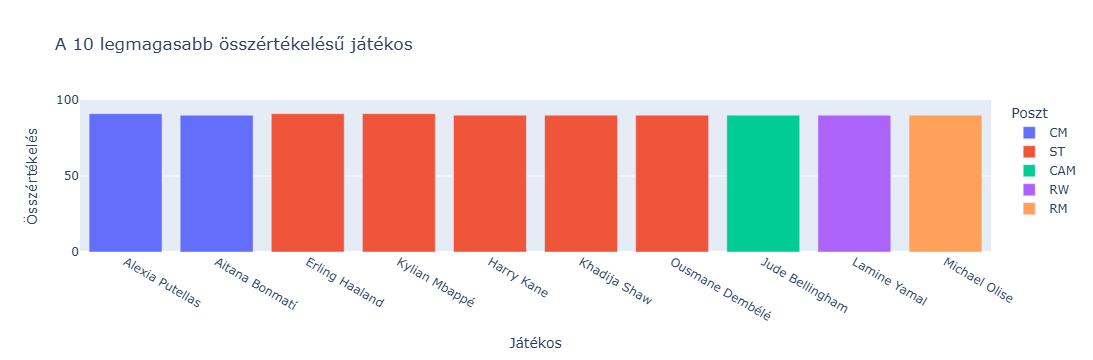

In [6]:
top10 = df.sort_values(["overall_rating", "nev"], ascending=[False, True]).head(10)
print(top10[["nev", "club", "position", "overall_rating"]].to_string(index=False))
fig = px.bar(top10, x="nev", y="overall_rating", color="position",
             title="A 10 legmagasabb összértékelésű játékos",
             labels={"nev":"Játékos", "overall_rating":"Összértékelés", "position":"Poszt"})
fig.update_yaxes(range=[0, 100])
fig.show()

In [7]:
print("1. válasz: A legmagasabb értékelés:", top10["overall_rating"].max())
print("Az ezzel az értékkel rendelkező játékosok:")
print(df.loc[df["overall_rating"] == df["overall_rating"].max(), "nev"].to_string(index=False))

1. válasz: A legmagasabb értékelés: 91
Az ezzel az értékkel rendelkező játékosok:
Alexia Putellas
  Kylian Mbappé
 Erling Haaland


## 5. Második kérdés: Melyik poszton a legmagasabb az átlagos összértékelés?
A `groupby()` posztonként csoportosít, a `mean()` átlagot számol.

position  overall_rating
     CDM           67.60
     CAM           67.57
      LM           67.17
      CB           67.13
      RM           67.05
      LW           67.05
      LB           66.70
      ST           66.61
      CM           66.58
      RW           66.53
      RB           66.47
      GK           65.06


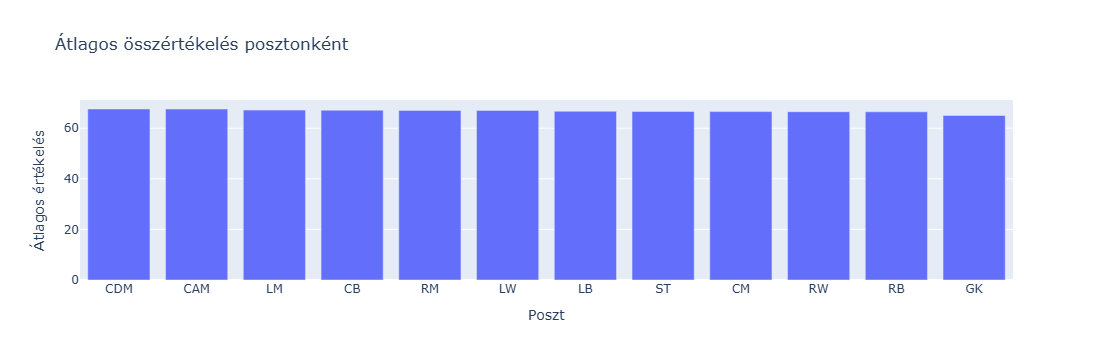

2. válasz: A legmagasabb átlagú poszt: CDM – 67.6


In [8]:
poszt_atlag = df.groupby("position", as_index=False)["overall_rating"].mean()
poszt_atlag = poszt_atlag.sort_values("overall_rating", ascending=False)
print(poszt_atlag.round(2).to_string(index=False))
fig = px.bar(poszt_atlag, x="position", y="overall_rating",
             title="Átlagos összértékelés posztonként",
             labels={"position":"Poszt", "overall_rating":"Átlagos értékelés"})
fig.show()
print("2. válasz: A legmagasabb átlagú poszt:", poszt_atlag.iloc[0]["position"],
      "–", round(poszt_atlag.iloc[0]["overall_rating"], 2))

## 6. Harmadik kérdés: Van kapcsolat a gyorsaság és az összértékelés között?
A kapusok gyorsasági főmutatója eltérően lehet kezelve, ezért csak a nem kapusokat vizsgáljuk. A korreláció -1 és +1 közötti szám: pozitív érték együtt növekedést, negatív érték ellentétes mozgást jelez; 0 körül nincs erős lineáris kapcsolat.

Korreláció: 0.256


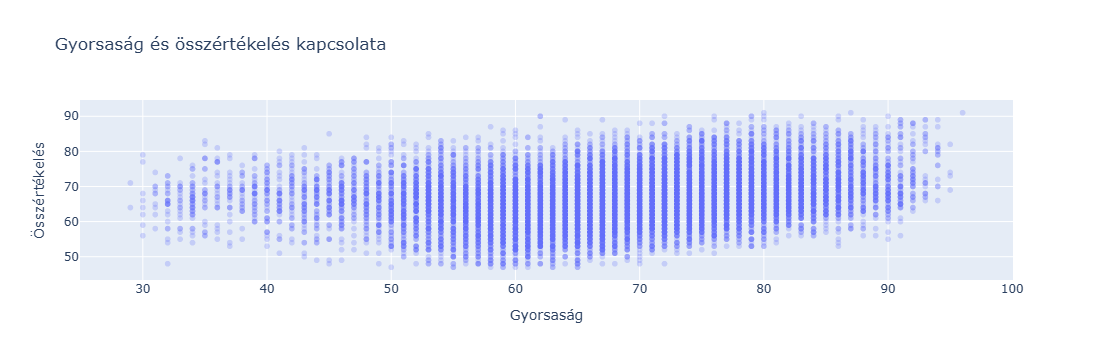

3. válasz: A korreláció értéke 0.256 – ez a két változó lineáris kapcsolatát méri, nem ok-okozatot.


In [9]:
gyorsasag = df.loc[df["position"] != "GK", ["pace", "overall_rating", "nev"]].dropna()
r = np.corrcoef(gyorsasag["pace"], gyorsasag["overall_rating"])[0, 1]
print("Korreláció:", round(r, 3))
fig = px.scatter(gyorsasag, x="pace", y="overall_rating", opacity=0.25,
                 title="Gyorsaság és összértékelés kapcsolata",
                 labels={"pace":"Gyorsaság", "overall_rating":"Összértékelés"},
                 hover_data=["nev"])
fig.show()
print("3. válasz: A korreláció értéke", round(r, 3),
      "– ez a két változó lineáris kapcsolatát méri, nem ok-okozatot.")

## 7. Negyedik kérdés: Mely országok rendelkeznek a legtöbb játékossal?
A `value_counts()` megszámolja, hányszor fordul elő egy ország neve.

       orszag  jatekosok_szama
      England             1527
      Germany             1390
        Spain             1210
       France             1081
    Argentina             1038
United States              729
        Italy              661
      Holland              521
       Brazil              469
       Norway              447


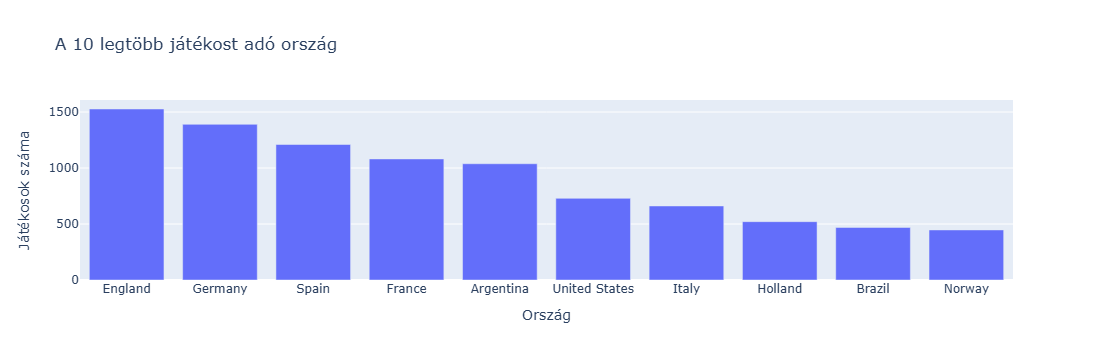

4. válasz: A legtöbb játékost adó ország: England – 1527 fő


In [10]:
orszagok = df["nationality"].dropna().value_counts().head(10).reset_index()
orszagok.columns = ["orszag", "jatekosok_szama"]
print(orszagok.to_string(index=False))
fig = px.bar(orszagok, x="orszag", y="jatekosok_szama",
             title="A 10 legtöbb játékost adó ország",
             labels={"orszag":"Ország", "jatekosok_szama":"Játékosok száma"})
fig.show()
print("4. válasz: A legtöbb játékost adó ország:", orszagok.iloc[0]["orszag"],
      "–", orszagok.iloc[0]["jatekosok_szama"], "fő")

## 8. Ötödik kérdés: Milyen kapcsolat van a lövés és a passzolás között?
A kapusokat itt is kihagyjuk, és csak a két értékkel rendelkező játékosokat hasonlítjuk össze.

Korreláció: 0.671


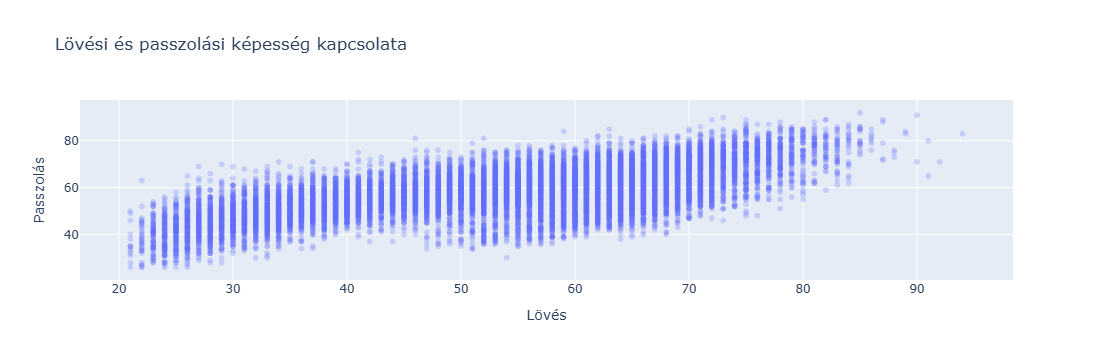

5. válasz: A korreláció értéke 0.671


In [11]:
tamadas = df.loc[df["position"] != "GK", ["shooting", "passing", "nev"]].dropna()
r2 = np.corrcoef(tamadas["shooting"], tamadas["passing"])[0, 1]
print("Korreláció:", round(r2, 3))
fig = px.scatter(tamadas, x="shooting", y="passing", opacity=0.25,
                 title="Lövési és passzolási képesség kapcsolata",
                 labels={"shooting":"Lövés", "passing":"Passzolás"}, hover_data=["nev"])
fig.show()
print("5. válasz: A korreláció értéke", round(r2, 3))

## 9. Összegzés
A vizsgálat öt kérdést elemzett: a legjobb játékosokat, a posztok átlagait, a gyorsaság és az értékelés kapcsolatát, a nemzetiségi megoszlást, valamint a lövés és passzolás kapcsolatát. A diagramok a Plotly segítségével készültek, az adatok kezelésére Pandast, a korreláció és átlag számítására NumPy-t használtunk.

**Korlátok:** Ez egy 2026. szeptember 12-i pillanatkép, nem élő adatbázis. Az EA játékbeli értékelései nem azonosak a valós futballteljesítménnyel. A korreláció nem bizonyít ok-okozati kapcsolatot.

**Forrás:** https://github.com/LakshmiKanth11/EA_FC_ANALYSIS

**Leadás előtt:** futtasd az összes cellát, ellenőrizd a grafikonokat és a kiírt eredményeket, majd mentsd a notebookot.